# Final Comparison — Klasifikasi BISINDO
## KNN vs Naive Bayes vs SVM

Notebook ini membandingkan secara komprehensif **9 model** dari 3 algoritma:
- **KNN**: k=3, k=5, k=7
- **Naive Bayes**: Gaussian, Complement, Bernoulli
- **SVM**: Linear, RBF, Polynomial

Metrik evaluasi: Accuracy, Precision, Recall, F1-Score, CV 5-Fold

## 1. Import Library & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings,os,time,json
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB,ComplementNB,BernoulliNB
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_val_score
from sklearn.preprocessing import LabelEncoder,StandardScaler,MinMaxScaler,Binarizer
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix
from sklearn.pipeline import Pipeline
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi']=120
plt.rcParams['font.size']=10
OUTPUT_DIR=r"E:\\Dokumen\\Kuliah\\Semester 5\\Pembelajaran Mesin\\Klasifikasi_Kelompok_1\\FinalComparison\\output"
os.makedirs(OUTPUT_DIR,exist_ok=True)
print('Setup selesai')

Setup selesai


## 2. Load & Prepare Dataset

In [2]:
DATA_PATH=r"E:\\Dokumen\\Kuliah\\Semester 5\\Pembelajaran Mesin\\Klasifikasi_Kelompok_1\\dataset_bisindo_landmarks.npz"
data=np.load(DATA_PATH,allow_pickle=True)
X=np.nan_to_num(data['X'].astype(np.float32))
labels=data['labels']
le=LabelEncoder()
y=le.fit_transform(labels)
class_names=le.classes_
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler=StandardScaler()
X_tr=scaler.fit_transform(X_train)
X_te=scaler.transform(X_test)
mm=MinMaxScaler()
X_tr_mm=mm.fit_transform(X_train)
X_te_mm=mm.transform(X_test)
binarizer=Binarizer(threshold=0.0)
X_tr_bin=binarizer.fit_transform(X_tr)
X_te_bin=binarizer.transform(X_te)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
print(f'Data siap | Train={X_tr.shape[0]}, Test={X_te.shape[0]}, Features={X_tr.shape[1]}')

Data siap | Train=6314, Test=1579, Features=127


## 3. Training Semua 9 Model

In [3]:
# Definisi semua model
models = [
    {'name':'KNN (k=3)',             'algo':'KNN',        'model': KNeighborsClassifier(n_neighbors=3,metric='euclidean',weights='distance',algorithm='ball_tree',n_jobs=-1), 'X_tr':X_tr,'X_te':X_te},
    {'name':'KNN (k=5)',             'algo':'KNN',        'model': KNeighborsClassifier(n_neighbors=5,metric='euclidean',weights='distance',algorithm='ball_tree',n_jobs=-1), 'X_tr':X_tr,'X_te':X_te},
    {'name':'KNN (k=7)',             'algo':'KNN',        'model': KNeighborsClassifier(n_neighbors=7,metric='euclidean',weights='distance',algorithm='ball_tree',n_jobs=-1), 'X_tr':X_tr,'X_te':X_te},
    {'name':'Naive Bayes Gaussian',  'algo':'NaiveBayes', 'model': GaussianNB(var_smoothing=1e-9),   'X_tr':X_tr,'X_te':X_te},
    {'name':'Naive Bayes Complement','algo':'NaiveBayes', 'model': ComplementNB(alpha=1.0),          'X_tr':X_tr_mm,'X_te':X_te_mm},
    {'name':'Naive Bayes Bernoulli', 'algo':'NaiveBayes', 'model': BernoulliNB(alpha=1.0),           'X_tr':X_tr_bin,'X_te':X_te_bin},
    {'name':'SVM Linear',            'algo':'SVM',        'model': SVC(kernel='linear',C=1.0,random_state=42),    'X_tr':X_tr,'X_te':X_te},
    {'name':'SVM RBF',               'algo':'SVM',        'model': SVC(kernel='rbf',C=10.0,gamma='scale',random_state=42),'X_tr':X_tr,'X_te':X_te},
    {'name':'SVM Polynomial',        'algo':'SVM',        'model': SVC(kernel='poly',C=1.0,degree=3,gamma='scale',random_state=42),'X_tr':X_tr,'X_te':X_te},
]

results=[]
print('Melatih semua 9 model...\n')
for m in models:
    t0=time.time();m['model'].fit(m['X_tr'],y_train);train_t=time.time()-t0
    t0=time.time();y_pred=m['model'].predict(m['X_te']);pred_t=time.time()-t0
    acc=accuracy_score(y_test,y_pred)
    prec=precision_score(y_test,y_pred,average='weighted',zero_division=0)
    rec=recall_score(y_test,y_pred,average='weighted',zero_division=0)
    f1=f1_score(y_test,y_pred,average='weighted',zero_division=0)
    results.append({'name':m['name'],'algo':m['algo'],'accuracy':acc,'precision':prec,'recall':rec,
                    'f1_score':f1,'train_time':train_t,'pred_time':pred_t,'y_pred':y_pred})
    print(f'{m["name"]:30s} | Acc={acc:.4f} | F1={f1:.4f} | Train={train_t:.2f}s')
print('\nSemua model selesai dilatih!')

Melatih semua 9 model...

KNN (k=3)                      | Acc=0.9614 | F1=0.9612 | Train=0.07s
KNN (k=5)                      | Acc=0.9550 | F1=0.9547 | Train=0.06s
KNN (k=7)                      | Acc=0.9506 | F1=0.9503 | Train=0.07s
Naive Bayes Gaussian           | Acc=0.4573 | F1=0.4004 | Train=0.01s
Naive Bayes Complement         | Acc=0.3711 | F1=0.3036 | Train=0.01s
Naive Bayes Bernoulli          | Acc=0.4630 | F1=0.4264 | Train=0.02s
SVM Linear                     | Acc=0.9702 | F1=0.9702 | Train=1.05s
SVM RBF                        | Acc=0.9791 | F1=0.9791 | Train=1.09s
SVM Polynomial                 | Acc=0.9208 | F1=0.9223 | Train=1.65s

Semua model selesai dilatih!


## 4. Cross-Validation 5-Fold Semua Model

In [4]:
print('Menjalankan 5-Fold CV untuk semua model...')
cv_configs = [
    ('KNN (k=3)',              Pipeline([('sc',StandardScaler()),('m',KNeighborsClassifier(n_neighbors=3,metric='euclidean',weights='distance',n_jobs=-1))])),
    ('KNN (k=5)',              Pipeline([('sc',StandardScaler()),('m',KNeighborsClassifier(n_neighbors=5,metric='euclidean',weights='distance',n_jobs=-1))])),
    ('KNN (k=7)',              Pipeline([('sc',StandardScaler()),('m',KNeighborsClassifier(n_neighbors=7,metric='euclidean',weights='distance',n_jobs=-1))])),
    ('Naive Bayes Gaussian',   Pipeline([('sc',StandardScaler()),('m',GaussianNB(var_smoothing=1e-9))])),
    ('Naive Bayes Complement', Pipeline([('mm',MinMaxScaler()),('m',ComplementNB(alpha=1.0))])),
    ('Naive Bayes Bernoulli',  Pipeline([('sc',StandardScaler()),('bn',Binarizer(threshold=0.0)),('m',BernoulliNB(alpha=1.0))])),
    ('SVM Linear',             Pipeline([('sc',StandardScaler()),('m',SVC(kernel='linear',C=1.0,random_state=42))])),
    ('SVM RBF',                Pipeline([('sc',StandardScaler()),('m',SVC(kernel='rbf',C=10.0,gamma='scale',random_state=42))])),
    ('SVM Polynomial',         Pipeline([('sc',StandardScaler()),('m',SVC(kernel='poly',C=1.0,degree=3,gamma='scale',random_state=42))])),
]
cv_results={}
for name,pipe in cv_configs:
    scores=cross_val_score(pipe,X,y,cv=cv,scoring='f1_weighted',n_jobs=-1)
    cv_results[name]={'mean':scores.mean(),'std':scores.std(),'scores':scores.tolist()}
    print(f'{name:30s} | CV F1 = {scores.mean():.4f} +/- {scores.std():.4f}')
# Update results dengan CV
for r in results:
    r['cv_f1_mean']=cv_results[r['name']]['mean']
    r['cv_f1_std']=cv_results[r['name']]['std']
print('\nCV selesai!')

Menjalankan 5-Fold CV untuk semua model...
KNN (k=3)                      | CV F1 = 0.9528 +/- 0.0017
KNN (k=5)                      | CV F1 = 0.9464 +/- 0.0030
KNN (k=7)                      | CV F1 = 0.9421 +/- 0.0027
Naive Bayes Gaussian           | CV F1 = 0.3545 +/- 0.0242
Naive Bayes Complement         | CV F1 = 0.3054 +/- 0.0136
Naive Bayes Bernoulli          | CV F1 = 0.4149 +/- 0.0015
SVM Linear                     | CV F1 = 0.9674 +/- 0.0029
SVM RBF                        | CV F1 = 0.9709 +/- 0.0040
SVM Polynomial                 | CV F1 = 0.9087 +/- 0.0051

CV selesai!


## 5. Tabel Perbandingan Lengkap

In [5]:
df=pd.DataFrame([{
    'Model':r['name'],'Algoritma':r['algo'],
    'Accuracy':r['accuracy'],'Precision':r['precision'],'Recall':r['recall'],'F1-Score':r['f1_score'],
    'CV F1 Mean':r['cv_f1_mean'],'CV F1 Std':r['cv_f1_std'],
    'Train Time (s)':r['train_time'],'Pred Time (s)':r['pred_time']
} for r in results])
df=df.sort_values('F1-Score',ascending=False).reset_index(drop=True)
df.index=df.index+1
df_display=df.copy()
for col in ['Accuracy','Precision','Recall','F1-Score','CV F1 Mean','CV F1 Std','Train Time (s)','Pred Time (s)']:
    df_display[col]=df_display[col].map(lambda x: f'{x:.4f}')
display(df_display.drop('Algoritma',axis=1).style
    .set_caption('🏆 Tabel Perbandingan Lengkap — 9 Model ML (Diurutkan F1-Score)')
    .set_properties(**{'text-align':'center','font-size':'11px'})
    .highlight_max(subset=['Accuracy','Precision','Recall','F1-Score','CV F1 Mean'],color='#b8f0b8')
    .highlight_min(subset=['Train Time (s)','Pred Time (s)'],color='#b8d8f0')
)
# Simpan ke CSV
df.to_csv(os.path.join(OUTPUT_DIR,'comparison_results.csv'),index=True)
print('Tabel disimpan ke comparison_results.csv')

,Model,Accuracy,Precision,Recall,F1-Score,CV F1 Mean,CV F1 Std,Train Time (s),Pred Time (s)
1,SVM RBF,0.9791,0.9797,0.9791,0.9791,0.9709,0.0040,1.0859,0.7311
2,SVM Linear,0.9702,0.9705,0.9702,0.9702,0.9674,0.0029,1.0489,0.3261
3,KNN (k=3),0.9614,0.9619,0.9614,0.9612,0.9528,0.0017,0.0681,0.2506
4,KNN (k=5),0.9550,0.9558,0.9550,0.9547,0.9464,0.0030,0.0595,0.2553
5,KNN (k=7),0.9506,0.9513,0.9506,0.9503,0.9421,0.0027,0.0664,0.2246
6,SVM Polynomial,0.9208,0.9301,0.9208,0.9223,0.9087,0.0051,1.6517,0.5531
7,Naive Bayes Bernoulli,0.4630,0.4698,0.4630,0.4264,0.4149,0.0015,0.0180,0.0043
8,Naive Bayes Gaussian,0.4573,0.4567,0.4573,0.4004,0.3545,0.0242,0.0087,0.0401
9,Naive Bayes Complement,0.3711,0.3667,0.3711,0.3036,0.3054,0.0136,0.0073,0.0015


Tabel disimpan ke comparison_results.csv


## 6. Bar Chart Perbandingan Metrik Utama

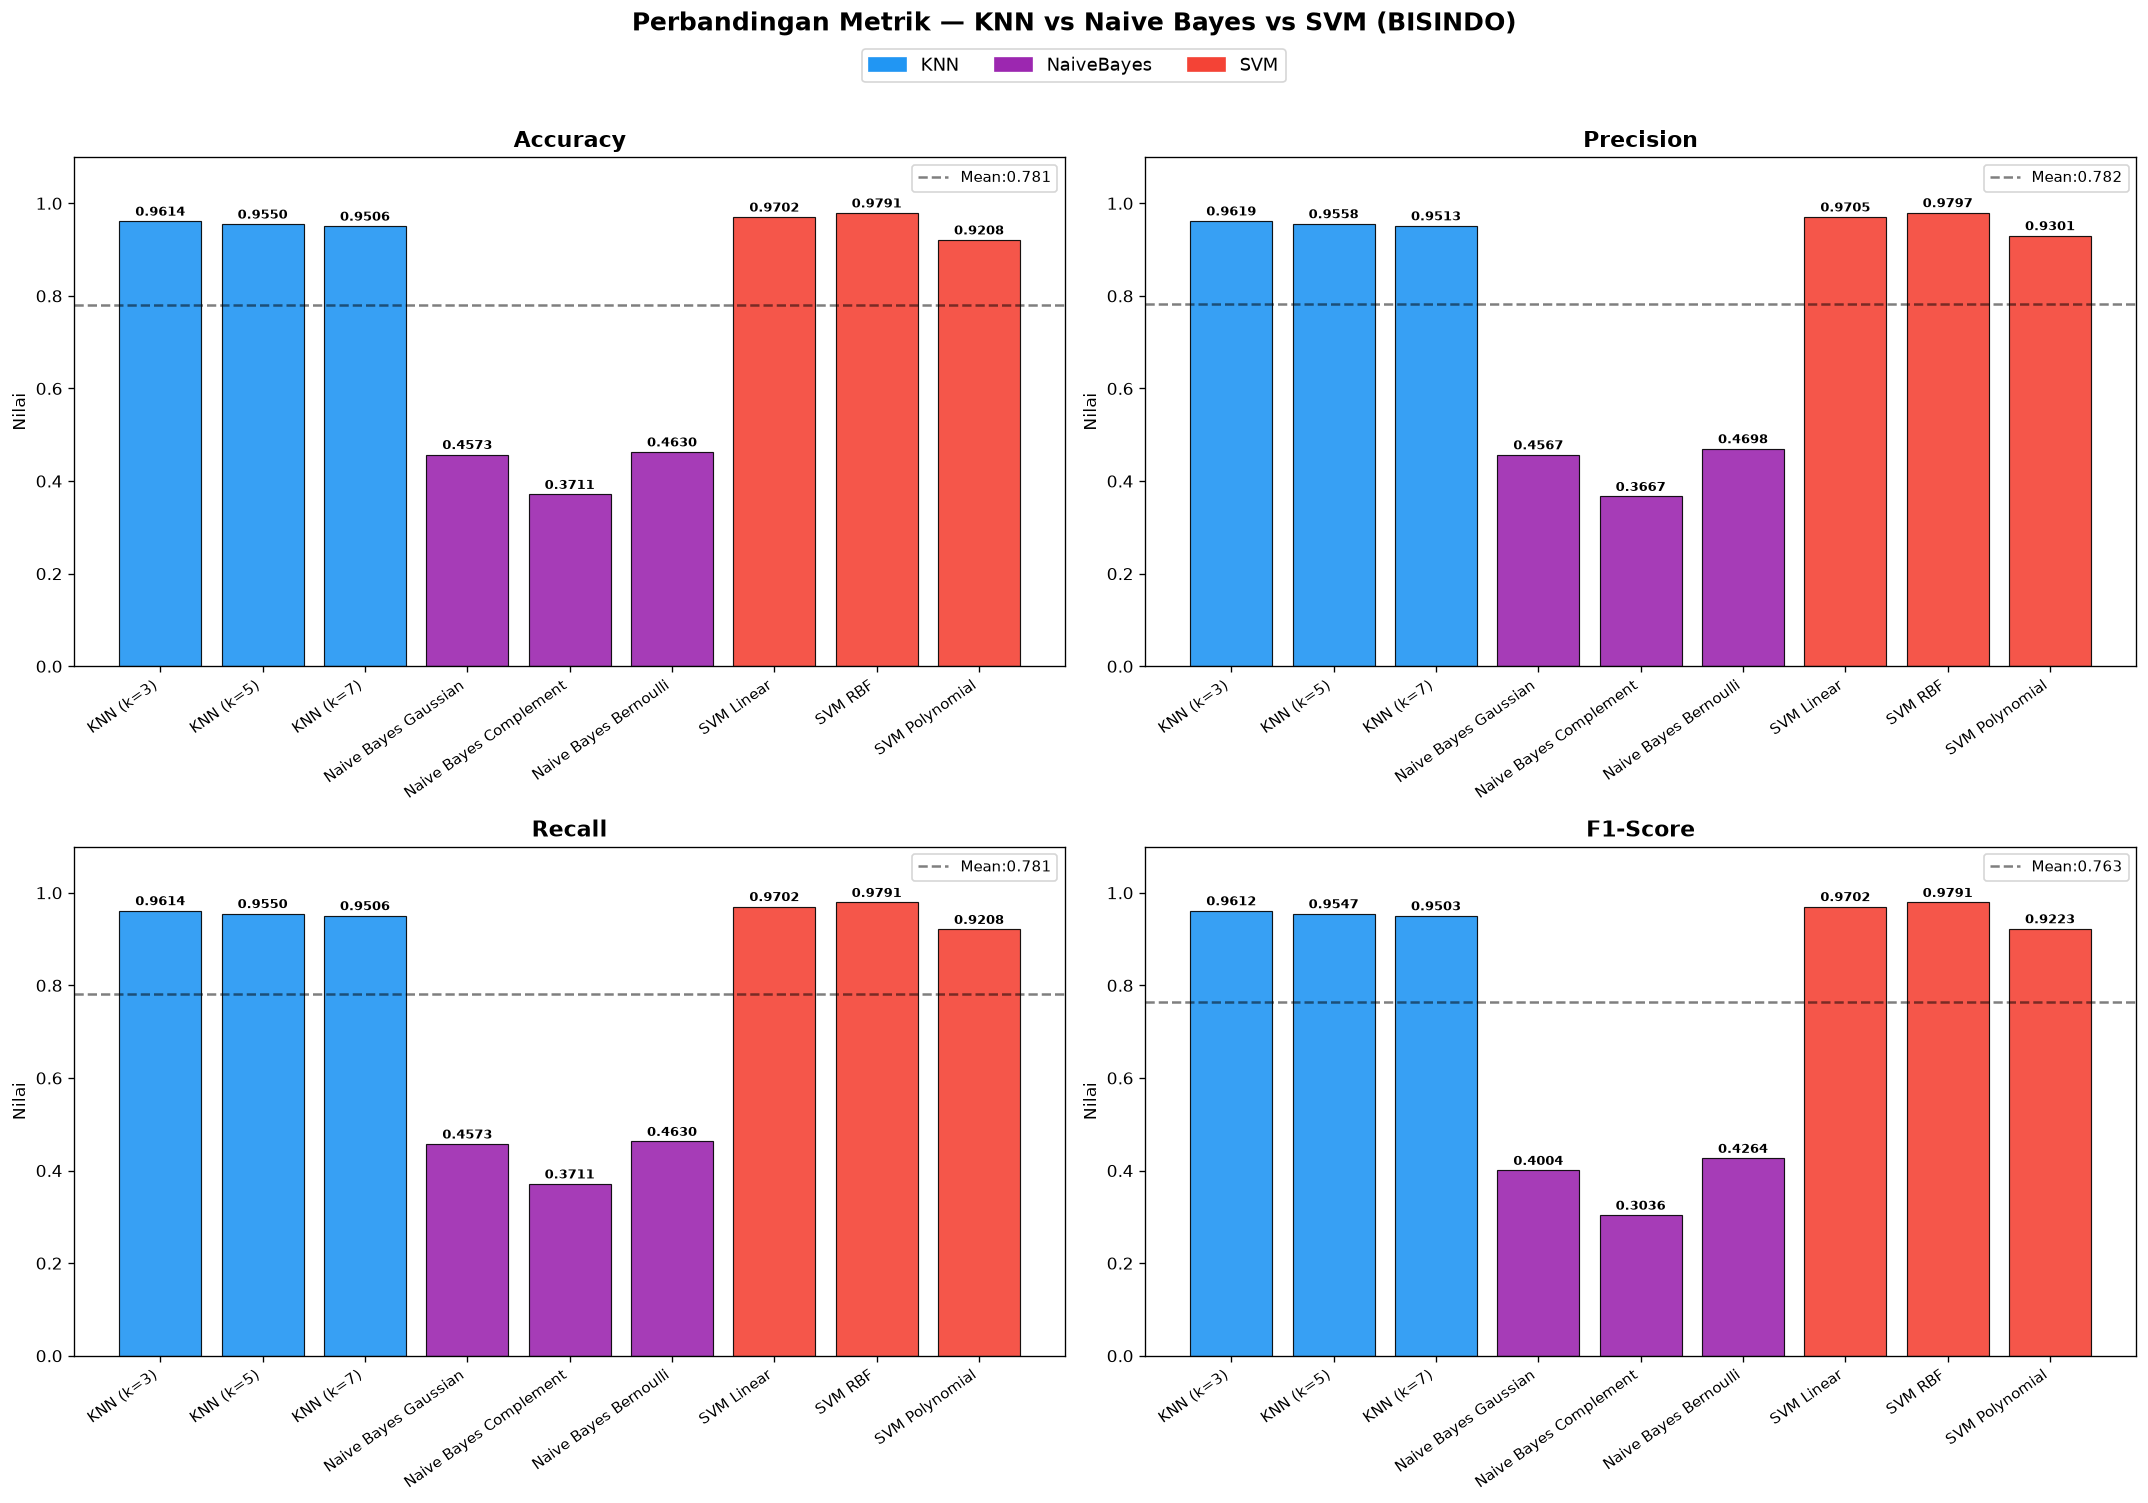

In [6]:
model_names=[r['name'] for r in results]
metrics=['accuracy','precision','recall','f1_score']
metric_labels=['Accuracy','Precision','Recall','F1-Score']

algo_colors={'KNN':'#2196F3','NaiveBayes':'#9C27B0','SVM':'#F44336'}
bar_colors=[algo_colors[r['algo']] for r in results]

fig,axes=plt.subplots(2,2,figsize=(18,12))
axes=axes.flatten()
for ax,metric,label in zip(axes,metrics,metric_labels):
    vals=[r[metric] for r in results]
    names=[r['name'] for r in results]
    bars=ax.bar(range(len(names)),vals,color=bar_colors,edgecolor='black',lw=0.7,alpha=0.9)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names,rotation=35,ha='right',fontsize=9)
    ax.set_ylim(0,1.1);ax.set_title(label,fontsize=13,fontweight='bold');ax.set_ylabel('Nilai')
    for bar,val in zip(bars,vals):
        ax.text(bar.get_x()+bar.get_width()/2.,bar.get_height()+0.005,f'{val:.4f}',
                ha='center',va='bottom',fontsize=8,fontweight='bold')
    ax.axhline(np.mean(vals),color='black',ls='--',alpha=0.5,label=f'Mean:{np.mean(vals):.3f}')
    ax.legend(fontsize=9)
legend_patches=[mpatches.Patch(color=c,label=l) for l,c in algo_colors.items()]
fig.legend(handles=legend_patches,loc='upper center',ncol=3,fontsize=11,bbox_to_anchor=(0.5,1.02))
plt.suptitle('Perbandingan Metrik — KNN vs Naive Bayes vs SVM (BISINDO)',fontsize=15,fontweight='bold',y=1.04)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'comparison_metrics_bar.png'),dpi=150,bbox_inches='tight')
plt.show()

## 7. Grouped Bar Chart per Algoritma

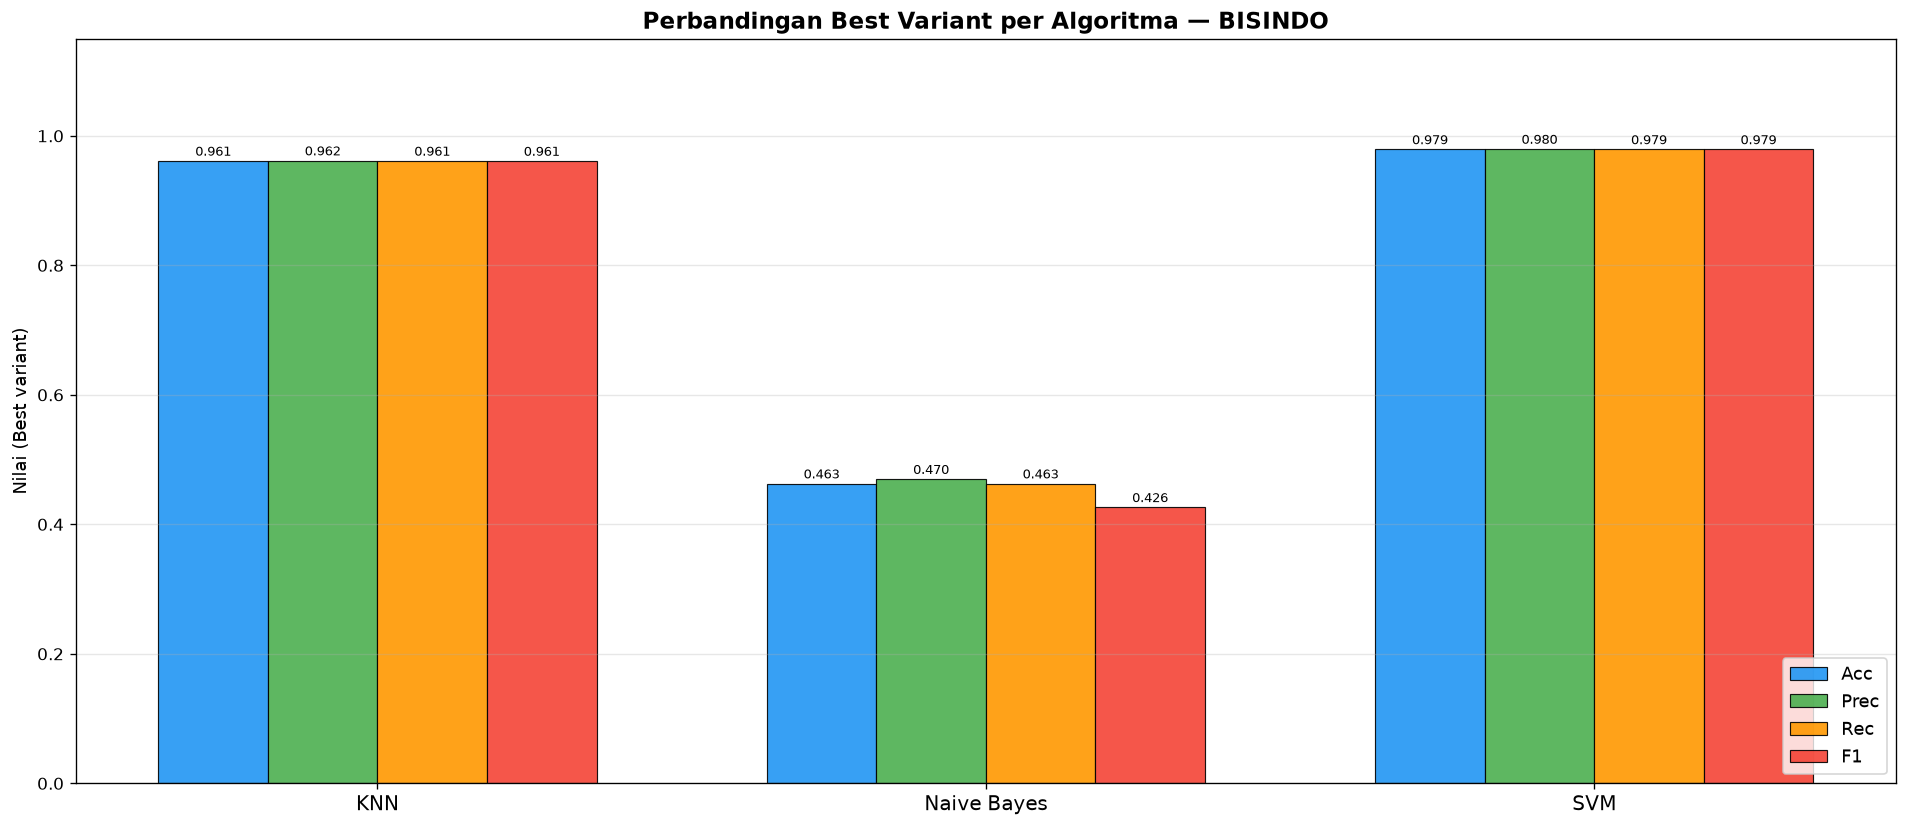

In [7]:
fig,ax=plt.subplots(figsize=(16,7))
algos=['KNN','NaiveBayes','SVM']
algo_labels=['KNN','Naive Bayes','SVM']
algo_models_list=[[r for r in results if r['algo']==a] for a in algos]
metrics2=['accuracy','precision','recall','f1_score']
metric_l2=['Acc','Prec','Rec','F1']
x=np.arange(len(algo_labels))
width=0.18
offsets=[-0.27,-0.09,0.09,0.27]
colors4=['#2196F3','#4CAF50','#FF9800','#F44336']
for i,(met,ml,c) in enumerate(zip(metrics2,metric_l2,colors4)):
    # Ambil nilai terbaik per algoritma
    best_vals=[max(r[met] for r in grp) for grp in algo_models_list]
    bars=ax.bar(x+offsets[i],best_vals,width,label=ml,color=c,edgecolor='black',lw=0.7,alpha=0.9)
    for bar,val in zip(bars,best_vals):
        ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.003,f'{val:.3f}',
                ha='center',va='bottom',fontsize=8)
ax.set_xticks(x);ax.set_xticklabels(algo_labels,fontsize=12)
ax.set_ylim(0,1.15);ax.set_ylabel('Nilai (Best variant)',fontsize=11)
ax.set_title('Perbandingan Best Variant per Algoritma — BISINDO',fontsize=14,fontweight='bold')
ax.legend(fontsize=11,loc='lower right')
ax.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'comparison_grouped_best.png'),dpi=150,bbox_inches='tight')
plt.show()

## 8. Radar Chart Perbandingan Semua Model

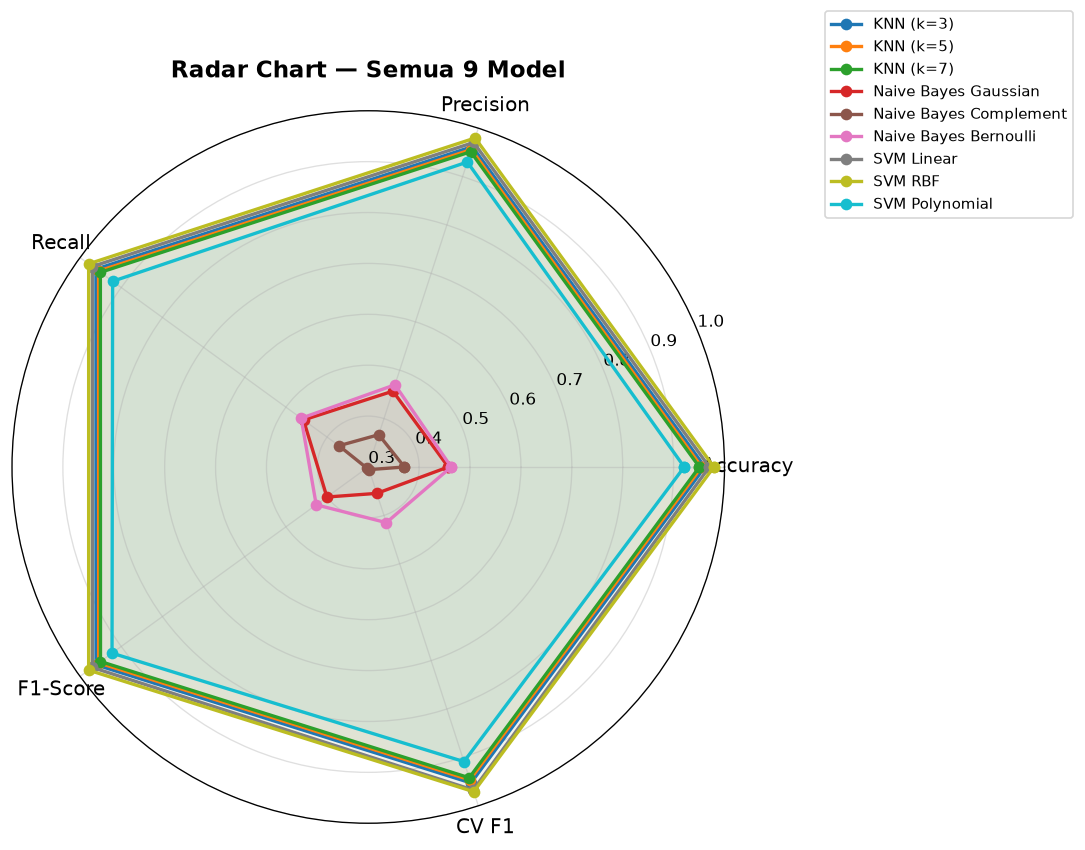

In [8]:
categories=['Accuracy','Precision','Recall','F1-Score','CV F1']
N=len(categories)
angles=[n/float(N)*2*np.pi for n in range(N)];angles+=angles[:1]
fig,ax=plt.subplots(figsize=(10,10),subplot_kw=dict(polar=True))
cmap=plt.get_cmap('tab10',len(results))
for i,r in enumerate(results):
    vals=[r['accuracy'],r['precision'],r['recall'],r['f1_score'],r['cv_f1_mean']]
    vals+=vals[:1]
    ax.plot(angles,vals,'o-',lw=2,color=cmap(i),label=r['name'])
    ax.fill(angles,vals,alpha=0.05,color=cmap(i))
ax.set_xticks(angles[:-1]);ax.set_xticklabels(categories,fontsize=12)
ax.set_ylim(0.3,1.0)
ax.set_title('Radar Chart — Semua 9 Model',fontsize=14,fontweight='bold',pad=20)
ax.legend(loc='upper right',bbox_to_anchor=(1.5,1.15),fontsize=9)
ax.grid(True,alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'radar_all_models.png'),dpi=150,bbox_inches='tight')
plt.show()

## 9. Heatmap Metrik Semua Model

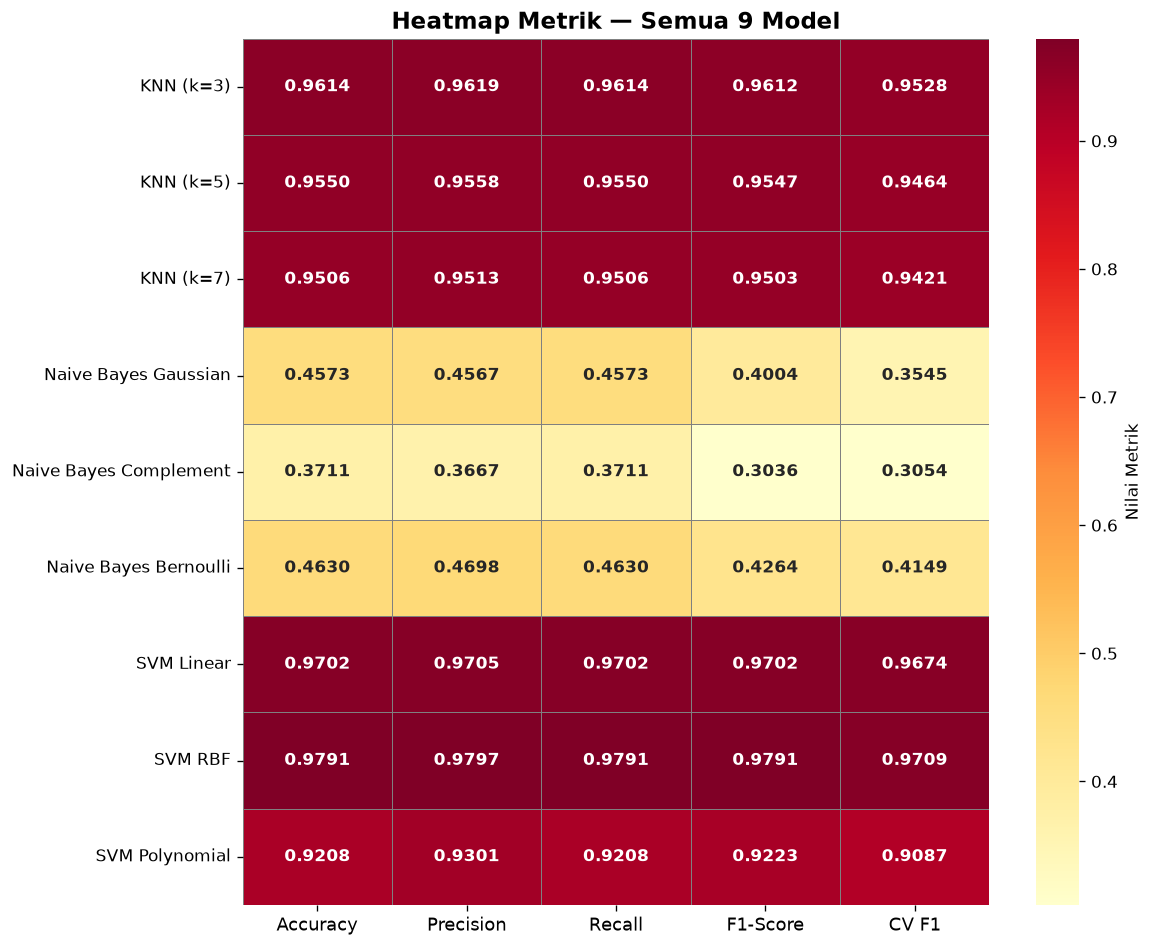

In [9]:
df_heat=pd.DataFrame(results)[['name','accuracy','precision','recall','f1_score','cv_f1_mean']]
df_heat=df_heat.set_index('name')
df_heat.columns=['Accuracy','Precision','Recall','F1-Score','CV F1']
fig,ax=plt.subplots(figsize=(10,8))
sns.heatmap(df_heat,annot=True,fmt='.4f',cmap='YlOrRd',ax=ax,
            linewidths=0.5,linecolor='gray',cbar_kws={'label':'Nilai Metrik'},
            annot_kws={'size':10,'fontweight':'bold'})
ax.set_title('Heatmap Metrik — Semua 9 Model',fontsize=14,fontweight='bold')
ax.set_ylabel('');ax.set_xlabel('')
plt.xticks(fontsize=11);plt.yticks(fontsize=10,rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'heatmap_all_models.png'),dpi=150,bbox_inches='tight')
plt.show()

## 10. Confusion Matrix Terbaik per Algoritma

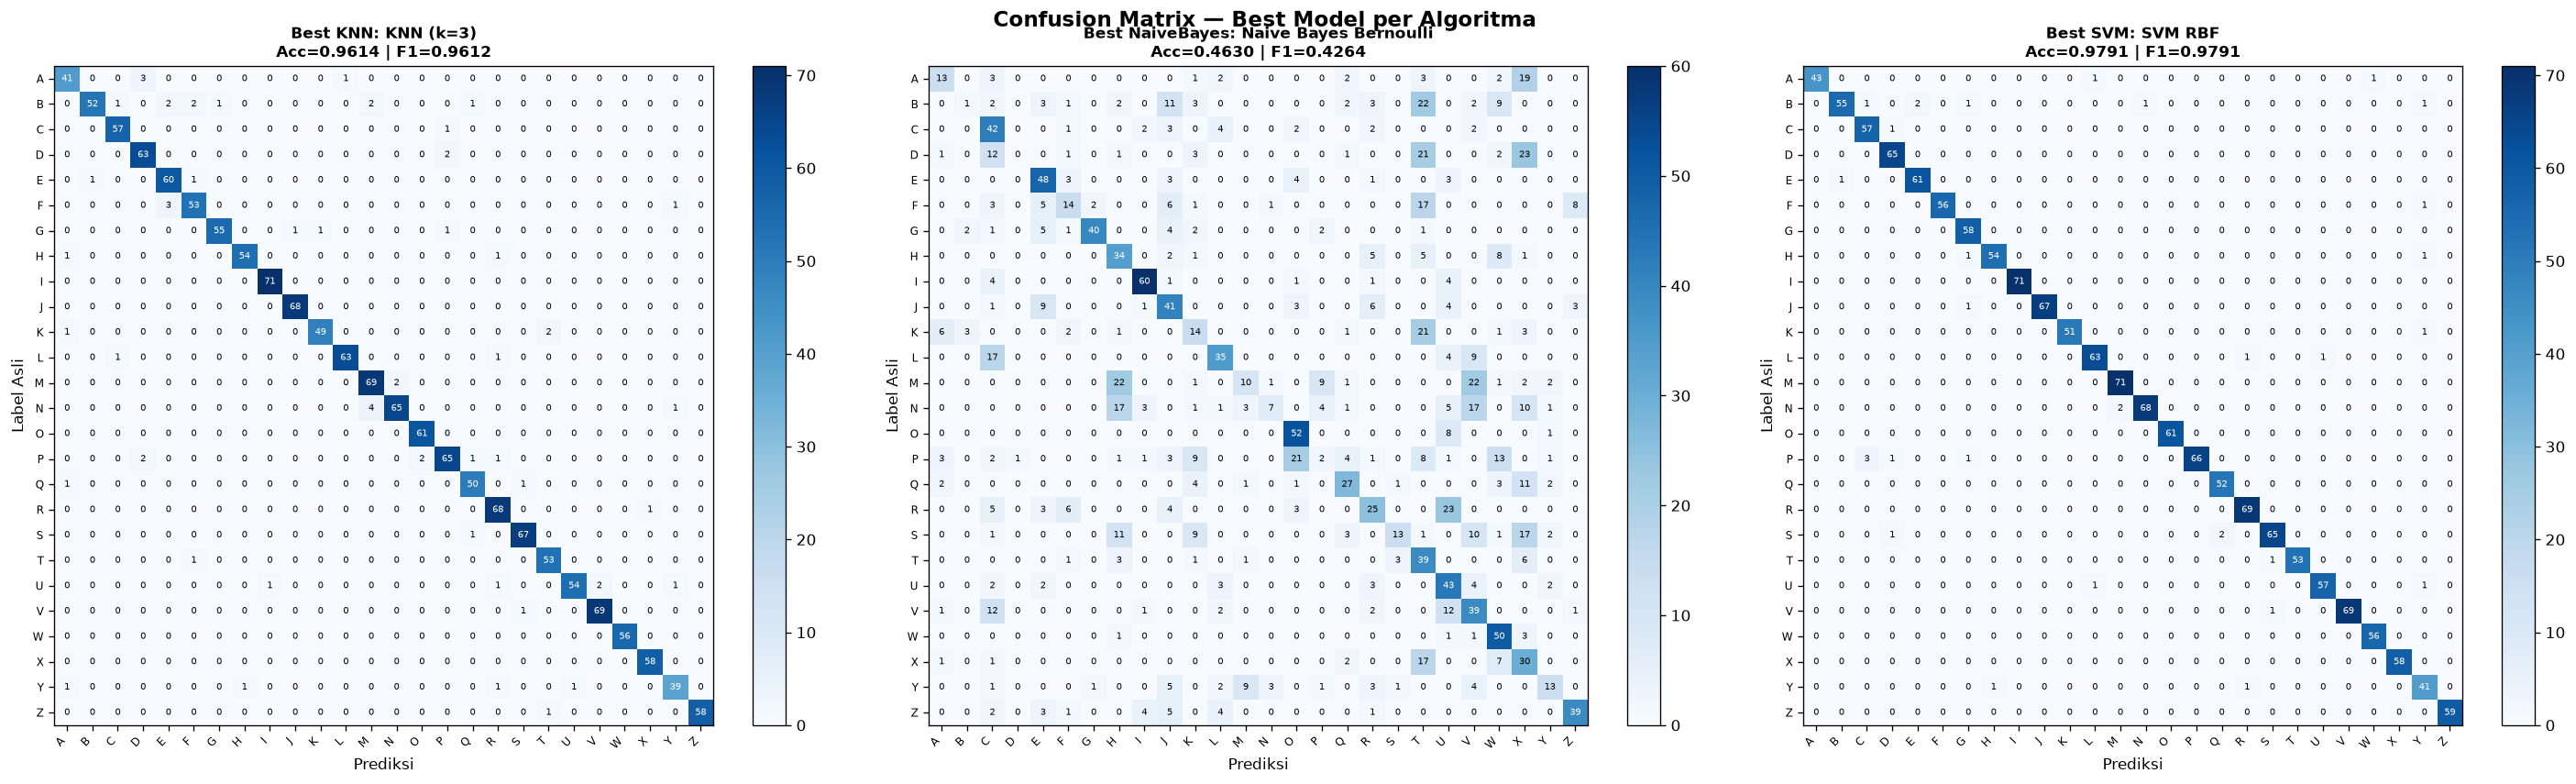

In [10]:
# Temukan model terbaik per algoritma
best_per_algo={}
for algo in ['KNN','NaiveBayes','SVM']:
    best=max([r for r in results if r['algo']==algo],key=lambda r:r['f1_score'])
    best_per_algo[algo]=best

fig,axes=plt.subplots(1,3,figsize=(24,7))
for ax,(algo,r) in zip(axes,best_per_algo.items()):
    cm=confusion_matrix(y_test,r['y_pred'])
    im=ax.imshow(cm,interpolation='nearest',cmap='Blues')
    plt.colorbar(im,ax=ax,fraction=0.046)
    thresh=cm.max()/2
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=6,
                    color='white' if cm[i,j]>thresh else 'black')
    ax.set_xticks(range(len(class_names)));ax.set_xticklabels(class_names,rotation=45,ha='right',fontsize=7)
    ax.set_yticks(range(len(class_names)));ax.set_yticklabels(class_names,fontsize=7)
    ax.set_xlabel('Prediksi');ax.set_ylabel('Label Asli')
    ax.set_title(f'Best {algo}: {r["name"]}\nAcc={r["accuracy"]:.4f} | F1={r["f1_score"]:.4f}',fontweight='bold',fontsize=10)
plt.suptitle('Confusion Matrix — Best Model per Algoritma',fontsize=14,fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'cm_best_per_algo.png'),dpi=150,bbox_inches='tight')
plt.show()

## 11. Analisis Waktu Training vs F1-Score

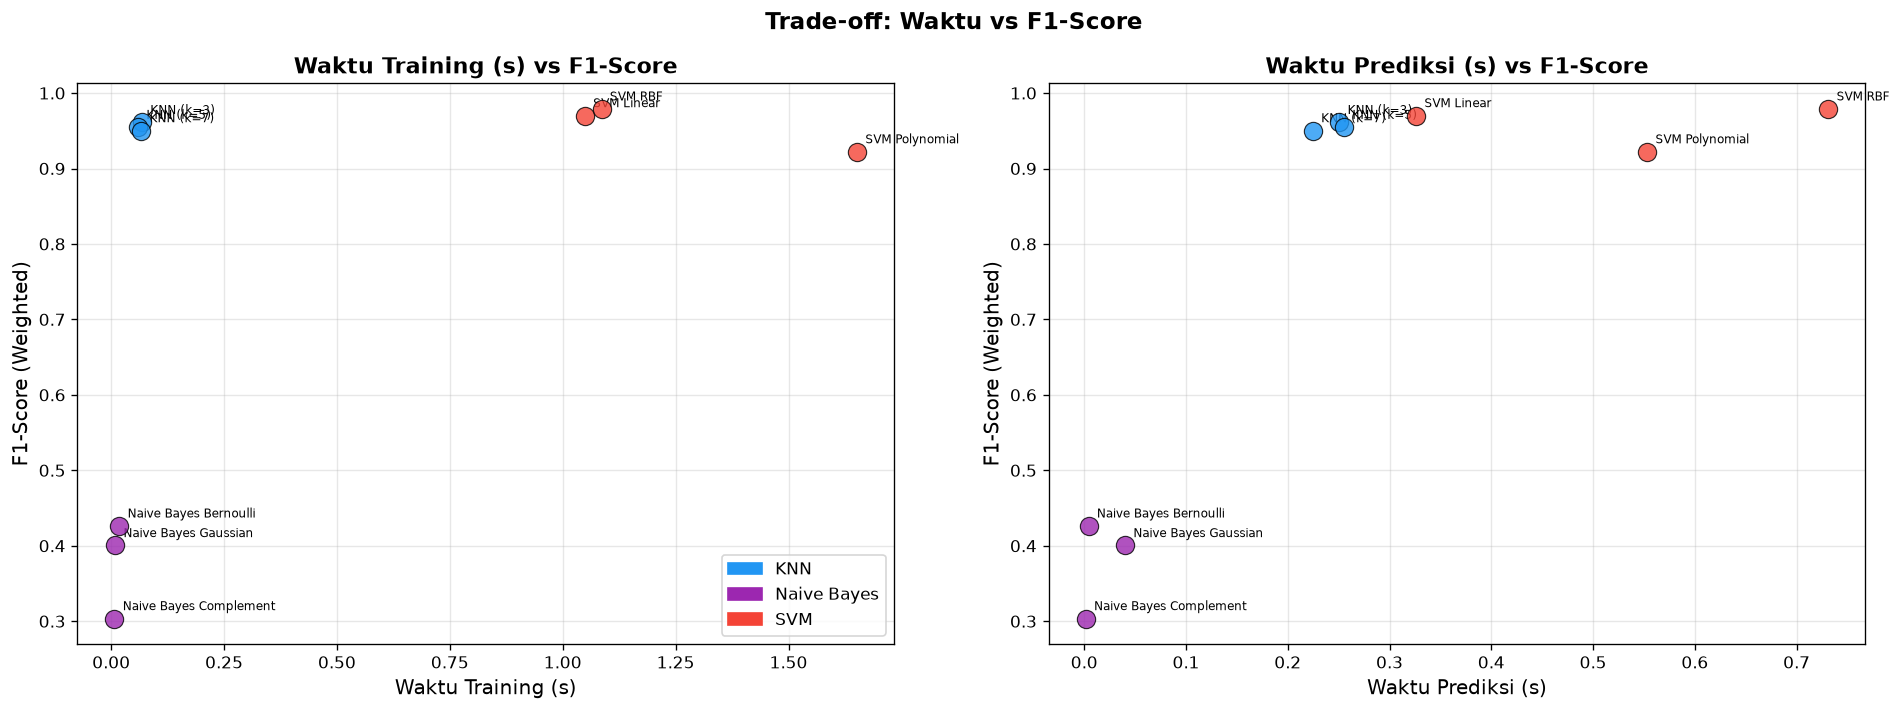

In [11]:
fig,axes=plt.subplots(1,2,figsize=(16,6))
algo_colors2={'KNN':'#2196F3','NaiveBayes':'#9C27B0','SVM':'#F44336'}
for ax,(xkey,xlabel) in zip(axes,[('train_time','Waktu Training (s)'),('pred_time','Waktu Prediksi (s)')]):
    for r in results:
        ax.scatter(r[xkey],r['f1_score'],s=120,
                   color=algo_colors2[r['algo']],alpha=0.8,edgecolors='black',lw=0.7,zorder=5)
        ax.annotate(r['name'],xy=(r[xkey],r['f1_score']),
                    xytext=(5,5),textcoords='offset points',fontsize=7)
    ax.set_xlabel(xlabel,fontsize=12);ax.set_ylabel('F1-Score (Weighted)',fontsize=12)
    ax.set_title(f'{xlabel} vs F1-Score',fontsize=13,fontweight='bold')
    ax.grid(True,alpha=0.3)
legend_patches2=[mpatches.Patch(color=c,label=l) for l,c in [('KNN','#2196F3'),('Naive Bayes','#9C27B0'),('SVM','#F44336')]]
axes[0].legend(handles=legend_patches2,fontsize=10)
plt.suptitle('Trade-off: Waktu vs F1-Score',fontsize=14,fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'tradeoff_time_f1.png'),dpi=150,bbox_inches='tight')
plt.show()

## 12. Kesimpulan & Rekomendasi

In [12]:
# Temukan model terbaik
best_model=max(results,key=lambda r:r['f1_score'])
best_cv=max(results,key=lambda r:r['cv_f1_mean'])
fastest=min(results,key=lambda r:r['train_time'])

print('='*65)
print('  KESIMPULAN PERBANDINGAN 9 MODEL ML — BISINDO')
print('='*65)
print(f'  Best F1-Score       : {best_model["name"]:25s} ({best_model["f1_score"]:.4f})')
print(f'  Best CV F1-Score    : {best_cv["name"]:25s} ({best_cv["cv_f1_mean"]:.4f})')
print(f'  Fastest Training    : {fastest["name"]:25s} ({fastest["train_time"]:.3f}s)')
print('='*65)

# Tabel ringkasan per Algoritma (best)
print('\nBest model per algoritma:')
for algo in ['KNN','NaiveBayes','SVM']:
    b=max([r for r in results if r['algo']==algo],key=lambda r:r['f1_score'])
    print(f'  {algo:12s}: {b["name"]:25s} | Acc={b["accuracy"]:.4f} | F1={b["f1_score"]:.4f} | CV={b["cv_f1_mean"]:.4f}')

df_final=pd.DataFrame(results).sort_values('f1_score',ascending=False)
print('\nRanking semua model:')
print(df_final[['name','accuracy','precision','recall','f1_score','cv_f1_mean']].to_string(index=False))

# Simpan JSON
final_export=[{k:v for k,v in r.items() if k!='y_pred'} for r in results]
with open(os.path.join(OUTPUT_DIR,'final_comparison.json'),'w') as f: json.dump(final_export,f,indent=2)
print('\nFinal comparison JSON disimpan!')
print('\nSemua notebook selesai! Cek folder FinalComparison/output untuk hasil.')

  KESIMPULAN PERBANDINGAN 9 MODEL ML — BISINDO
  Best F1-Score       : SVM RBF                   (0.9791)
  Best CV F1-Score    : SVM RBF                   (0.9709)
  Fastest Training    : Naive Bayes Complement    (0.007s)

Best model per algoritma:
  KNN         : KNN (k=3)                 | Acc=0.9614 | F1=0.9612 | CV=0.9528
  NaiveBayes  : Naive Bayes Bernoulli     | Acc=0.4630 | F1=0.4264 | CV=0.4149
  SVM         : SVM RBF                   | Acc=0.9791 | F1=0.9791 | CV=0.9709

Ranking semua model:
                  name  accuracy  precision   recall  f1_score  cv_f1_mean
               SVM RBF  0.979101   0.979721 0.979101  0.979104    0.970913
            SVM Linear  0.970234   0.970459 0.970234  0.970174    0.967353
             KNN (k=3)  0.961368   0.961874 0.961368  0.961196    0.952794
             KNN (k=5)  0.955035   0.955801 0.955035  0.954717    0.946420
             KNN (k=7)  0.950602   0.951307 0.950602  0.950304    0.942064
        SVM Polynomial  0.920836   0.930